In [15]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

# 1. Load the dataset
digits = load_digits()

# 2. Normalize input values to the range [0, 1]
X = digits.data.astype(np.float64) / 16.0

# 3. Get the actual digit labels
y = digits.target

# 4. One-hot encode the labels
Y = np.eye(10)[y]

# 5. Split the dataset into 70% training and 30% testing
X_train, X_test, Y_train, Y_test, y_train, y_test = train_test_split(
    X, Y, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# 6. Check the dataset dimensions
print("Training data:", X_train.shape)
print("Test data:", X_test.shape)
print("Training labels:", Y_train.shape)
print("Test labels:", Y_test.shape)


Training data: (1257, 64)
Test data: (540, 64)
Training labels: (1257, 10)
Test labels: (540, 10)


In [3]:

# Neural Network Architecture

np.random.seed(42)

input_size = 64
hidden_size = 16
output_size = 10

# Layer 1
W1 = np.random.randn(input_size, hidden_size) * 0.01
b1 = np.zeros(hidden_size)

# Layer 2
W2 = np.random.randn(hidden_size, hidden_size) * 0.01
b2 = np.zeros(hidden_size)

# Output Layer
W3 = np.random.randn(hidden_size, output_size) * 0.01
b3 = np.zeros(output_size)

print("W1 shape:", W1.shape)
print("W2 shape:", W2.shape)
print("W3 shape:", W3.shape)

print("Neural Network initialized successfully!")


W1 shape: (64, 16)
W2 shape: (16, 16)
W3 shape: (16, 10)
Neural Network initialized successfully!


In [4]:

# ReLU activation function
def relu(x):
    return np.maximum(0, x)

# Softmax activation function
def softmax(x):
    x = x - np.max(x, axis=1, keepdims=True)
    exp_x = np.exp(x)
    return exp_x / np.sum(exp_x, axis=1, keepdims=True)

# Forward propagation
def forward(X):
    Z1 = X @ W1 + b1
    A1 = relu(Z1)

    Z2 = A1 @ W2 + b2
    A2 = relu(Z2)

    Z3 = A2 @ W3 + b3
    A3 = softmax(Z3)

    return A3

# Test with 5 images
predictions = forward(X_train[:5])

print("Output shape:", predictions.shape)
print("Probability sums:", predictions.sum(axis=1))
print("First prediction:", predictions[0])


Output shape: (5, 10)
Probability sums: [1. 1. 1. 1. 1.]
First prediction: [0.09999922 0.10000441 0.10000404 0.10000234 0.10000207 0.09999305
 0.09999366 0.10000383 0.0999994  0.09999799]


In [5]:

# Cross-Entropy Loss Function

def cross_entropy_loss(y_true, y_pred):
    y_pred = np.clip(y_pred, 1e-12, 1.0)

    loss = -np.mean(
        np.sum(y_true * np.log(y_pred), axis=1)
    )

    return loss


# Calculate initial loss before training
initial_predictions = forward(X_train)

initial_loss = cross_entropy_loss(
    Y_train, initial_predictions
)

print("Initial Loss:", initial_loss)
print("Expected Loss:", np.log(10))

# Check if loss is close to expected value
print(
    "Loss sanity check:",
    np.isclose(initial_loss, np.log(10), atol=0.01)
)


Initial Loss: 2.3025834945705626
Expected Loss: 2.302585092994046
Loss sanity check: True


In [6]:

# Backpropagation using the Chain Rule

def backward(X_batch, Y_batch):
    m = X_batch.shape[0]

    # Forward pass
    Z1 = X_batch @ W1 + b1
    A1 = relu(Z1)

    Z2 = A1 @ W2 + b2
    A2 = relu(Z2)

    Z3 = A2 @ W3 + b3
    A3 = softmax(Z3)

    # Output layer gradients
    dZ3 = (A3 - Y_batch) / m
    dW3 = A2.T @ dZ3
    db3 = np.sum(dZ3, axis=0)

    # Hidden layer 2 gradients
    dA2 = dZ3 @ W3.T
    dZ2 = dA2 * (Z2 > 0)
    dW2 = A1.T @ dZ2
    db2 = np.sum(dZ2, axis=0)

    # Hidden layer 1 gradients
    dA1 = dZ2 @ W2.T
    dZ1 = dA1 * (Z1 > 0)
    dW1 = X_batch.T @ dZ1
    db1 = np.sum(dZ1, axis=0)

    return {
        "W1": dW1, "b1": db1,
        "W2": dW2, "b2": db2,
        "W3": dW3, "b3": db3
    }


# Test Backpropagation
gradients = backward(X_train[:32], Y_train[:32])

print("dW1 shape:", gradients["W1"].shape)
print("dW2 shape:", gradients["W2"].shape)
print("dW3 shape:", gradients["W3"].shape)
print("Backpropagation completed!")


dW1 shape: (64, 16)
dW2 shape: (16, 16)
dW3 shape: (16, 10)
Backpropagation completed!


In [7]:

# Numerical Gradient Checking

epsilon = 1e-5

# Use a small batch for gradient checking
X_small = X_train[:8]
Y_small = Y_train[:8]

# Analytical gradients
grads = backward(X_small, Y_small)

weights = {
    "W1": W1,
    "W2": W2,
    "W3": W3
}

rng = np.random.default_rng(42)

passed = 0
total = 0

# Check random weights from all 3 layers
for name, count in [("W1", 4), ("W2", 3), ("W3", 3)]:
    weight = weights[name]

    # Avoid near-zero gradients that are
    # numerically unstable in relative error
    candidates = np.argwhere(
        np.abs(grads[name]) > 1e-5
    )

    selected = candidates[
        rng.choice(len(candidates), size=count, replace=False)
    ]

    for i, j in selected:
        original = weight[i, j]

        # Positive perturbation
        weight[i, j] = original + epsilon
        loss_plus = cross_entropy_loss(
            Y_small, forward(X_small)
        )

        # Negative perturbation
        weight[i, j] = original - epsilon
        loss_minus = cross_entropy_loss(
            Y_small, forward(X_small)
        )

        # Restore original weight
        weight[i, j] = original

        numerical = (loss_plus - loss_minus) / (2 * epsilon)
        analytical = grads[name][i, j]

        relative_error = abs(numerical - analytical) / max(
            1e-12, abs(numerical) + abs(analytical)
        )

        total += 1
        if relative_error < 1e-6:
            passed += 1

        print(
            f"{name}[{i},{j}]: "
            f"relative error = {relative_error:.2e}"
        )

print("----------------------------")
print(f"Gradient Check: {passed}/{total} passed")
print("Result:", "PASS" if passed >= 9 else "FAIL")


W1[27,1]: relative error = 1.78e-07
W1[5,5]: relative error = 9.70e-08
W1[41,2]: relative error = 4.11e-07
W1[46,7]: relative error = 5.12e-08
W2[9,11]: relative error = 1.34e-07
W2[1,5]: relative error = 5.25e-08
W2[2,14]: relative error = 1.25e-07
W3[12,1]: relative error = 3.52e-09
W3[12,4]: relative error = 9.80e-09
W3[12,0]: relative error = 1.60e-08
----------------------------
Gradient Check: 10/10 passed
Result: PASS


In [8]:

# Initialize a new network
def initialize_parameters(width, seed=42):
    rng = np.random.default_rng(seed)

    return {
        "W1": rng.standard_normal((64, width)) * 0.01,
        "b1": np.zeros(width),
        "W2": rng.standard_normal((width, width)) * 0.01,
        "b2": np.zeros(width),
        "W3": rng.standard_normal((width, 10)) * 0.01,
        "b3": np.zeros(10)
    }


# Forward propagation
def model_forward(X, params):
    Z1 = X @ params["W1"] + params["b1"]
    A1 = relu(Z1)

    Z2 = A1 @ params["W2"] + params["b2"]
    A2 = relu(Z2)

    Z3 = A2 @ params["W3"] + params["b3"]
    P = softmax(Z3)

    cache = (X, Z1, A1, Z2, A2, P)
    return P, cache


# Backpropagation
def model_backward(Y, params, cache):
    X, Z1, A1, Z2, A2, P = cache
    m = len(X)

    dZ3 = (P - Y) / m
    dW3 = A2.T @ dZ3
    db3 = np.sum(dZ3, axis=0)

    dZ2 = (dZ3 @ params["W3"].T) * (Z2 > 0)
    dW2 = A1.T @ dZ2
    db2 = np.sum(dZ2, axis=0)

    dZ1 = (dZ2 @ params["W2"].T) * (Z1 > 0)
    dW1 = X.T @ dZ1
    db1 = np.sum(dZ1, axis=0)

    return {
        "W1": dW1, "b1": db1,
        "W2": dW2, "b2": db2,
        "W3": dW3, "b3": db3
    }


# Training loop
def train_model(width, learning_rate, epochs=50):
    params = initialize_parameters(width)
    rng = np.random.default_rng(42)
    losses = []

    for epoch in range(1, epochs + 1):

        # Shuffle training data
        indices = rng.permutation(len(X_train))

        # Mini-batches of size 32
        for start in range(0, len(X_train), 32):
            batch_ids = indices[start:start + 32]
            X_batch = X_train[batch_ids]
            Y_batch = Y_train[batch_ids]

            predictions, cache = model_forward(
                X_batch, params
            )

            grads = model_backward(
                Y_batch, params, cache
            )

            # Gradient descent
            for key in params:
                params[key] -= learning_rate * grads[key]

        # Record loss after each epoch
        train_predictions, _ = model_forward(
            X_train, params
        )

        loss = cross_entropy_loss(
            Y_train, train_predictions
        )
        losses.append(loss)

        print(
            f"W={width}, LR={learning_rate}, "
            f"Epoch {epoch}/50, Loss={loss:.6f}"
        )

    # Test accuracy
    test_predictions, _ = model_forward(
        X_test, params
    )

    predicted_labels = np.argmax(
        test_predictions, axis=1
    )

    accuracy = np.mean(predicted_labels == y_test)

    print(
        f"Final Test Accuracy: {accuracy * 100:.2f}%"
    )

    return params, losses, accuracy


print("Training functions ready!")


Training functions ready!


In [9]:

# Train all 6 configurations

learning_rates = [0.001, 0.01, 0.1]
hidden_widths = [16, 64]

results = {}

for width in hidden_widths:
    for lr in learning_rates:

        print("\n-------------------------")
        print(f"Training: Width={width}, LR={lr}")
        print("-------------------------")

        params, losses, accuracy = train_model(
            width=width,
            learning_rate=lr,
            epochs=50
        )

        results[(width, lr)] = {
            "params": params,
            "losses": losses,
            "accuracy": accuracy
        }

print("\nALL TRAINING COMPLETED!")



-------------------------
Training: Width=16, LR=0.001
-------------------------
W=16, LR=0.001, Epoch 1/50, Loss=2.302585
W=16, LR=0.001, Epoch 2/50, Loss=2.302583
W=16, LR=0.001, Epoch 3/50, Loss=2.302583
W=16, LR=0.001, Epoch 4/50, Loss=2.302582
W=16, LR=0.001, Epoch 5/50, Loss=2.302582
W=16, LR=0.001, Epoch 6/50, Loss=2.302581
W=16, LR=0.001, Epoch 7/50, Loss=2.302580
W=16, LR=0.001, Epoch 8/50, Loss=2.302579
W=16, LR=0.001, Epoch 9/50, Loss=2.302578
W=16, LR=0.001, Epoch 10/50, Loss=2.302577
W=16, LR=0.001, Epoch 11/50, Loss=2.302576
W=16, LR=0.001, Epoch 12/50, Loss=2.302575
W=16, LR=0.001, Epoch 13/50, Loss=2.302574
W=16, LR=0.001, Epoch 14/50, Loss=2.302573
W=16, LR=0.001, Epoch 15/50, Loss=2.302572
W=16, LR=0.001, Epoch 16/50, Loss=2.302572
W=16, LR=0.001, Epoch 17/50, Loss=2.302571
W=16, LR=0.001, Epoch 18/50, Loss=2.302571
W=16, LR=0.001, Epoch 19/50, Loss=2.302570
W=16, LR=0.001, Epoch 20/50, Loss=2.302569
W=16, LR=0.001, Epoch 21/50, Loss=2.302569
W=16, LR=0.001, Epoch 22

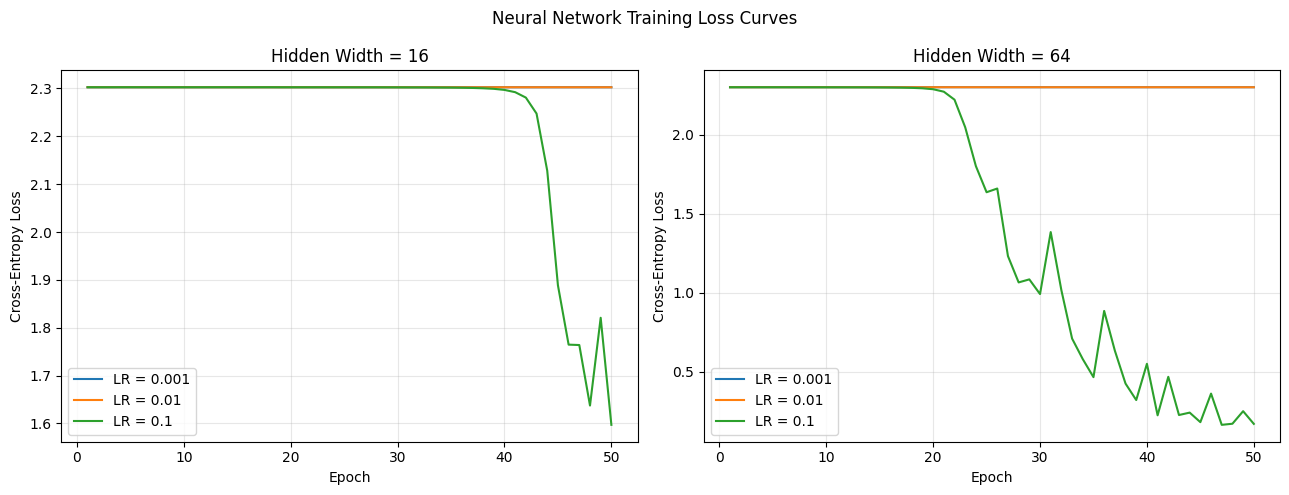

Saved: results/loss_curves.png


In [10]:

import os

os.makedirs("results", exist_ok=True)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, width in zip(axes, hidden_widths):

    for lr in learning_rates:
        losses = results[(width, lr)]["losses"]

        ax.plot(
            range(1, 51),
            losses,
            label=f"LR = {lr}"
        )

    ax.set_title(f"Hidden Width = {width}")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Cross-Entropy Loss")
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.suptitle("Neural Network Training Loss Curves")
plt.tight_layout()

plt.savefig(
    "results/loss_curves.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

print("Saved: results/loss_curves.png")


In [11]:

print("FINAL TEST ACCURACY")
print("----------------------------")

for width in hidden_widths:
    for lr in learning_rates:
        accuracy = results[(width, lr)]["accuracy"]

        print(
            f"Width={width}, "
            f"LR={lr}: "
            f"Accuracy={accuracy * 100:.2f}%"
        )


FINAL TEST ACCURACY
----------------------------
Width=16, LR=0.001: Accuracy=10.19%
Width=16, LR=0.01: Accuracy=10.19%
Width=16, LR=0.1: Accuracy=32.59%
Width=64, LR=0.001: Accuracy=10.19%
Width=64, LR=0.01: Accuracy=10.19%
Width=64, LR=0.1: Accuracy=93.89%


In [12]:

import time
import os

# Measure forward and backward execution time
def measure_timing(width, learning_rate=0.1, runs=100):

    params = results[(width, learning_rate)]["params"]

    X_batch = X_train[:32]
    Y_batch = Y_train[:32]

    # Warm-up runs
    for _ in range(10):
        predictions, cache = model_forward(
            X_batch, params
        )
        grads = model_backward(
            Y_batch, params, cache
        )

    forward_times = []
    backward_times = []

    for _ in range(runs):

        # Measure forward propagation
        start = time.perf_counter()

        predictions, cache = model_forward(
            X_batch, params
        )

        end = time.perf_counter()

        forward_times.append((end - start) * 1000)

        # Measure backward propagation
        start = time.perf_counter()

        grads = model_backward(
            Y_batch, params, cache
        )

        end = time.perf_counter()

        backward_times.append((end - start) * 1000)

    forward_median = np.median(forward_times)
    backward_median = np.median(backward_times)

    return forward_median, backward_median


# Test both network widths
timing_results = {}

for width in [16, 64]:

    forward_time, backward_time = measure_timing(width)

    timing_results[width] = (
        forward_time, backward_time
    )

    print(f"\nHidden Width = {width}")
    print(f"Forward Median: {forward_time:.4f} ms")
    print(f"Backward Median: {backward_time:.4f} ms")

    if backward_time > forward_time:
        print("Backward propagation is slower.")
    else:
        print("Forward propagation is slower.")


# Save the timing report
os.makedirs("results", exist_ok=True)

with open("results/timing_breakdown.txt", "w") as f:
    for width, (ft, bt) in timing_results.items():
        f.write(f"Hidden Width: {width}\n")
        f.write(f"Forward Median: {ft:.4f} ms\n")
        f.write(f"Backward Median: {bt:.4f} ms\n\n")

print("\nTiming report saved!")



Hidden Width = 16
Forward Median: 0.0134 ms
Backward Median: 0.0140 ms
Backward propagation is slower.

Hidden Width = 64
Forward Median: 0.0336 ms
Backward Median: 0.0360 ms
Backward propagation is slower.

Timing report saved!


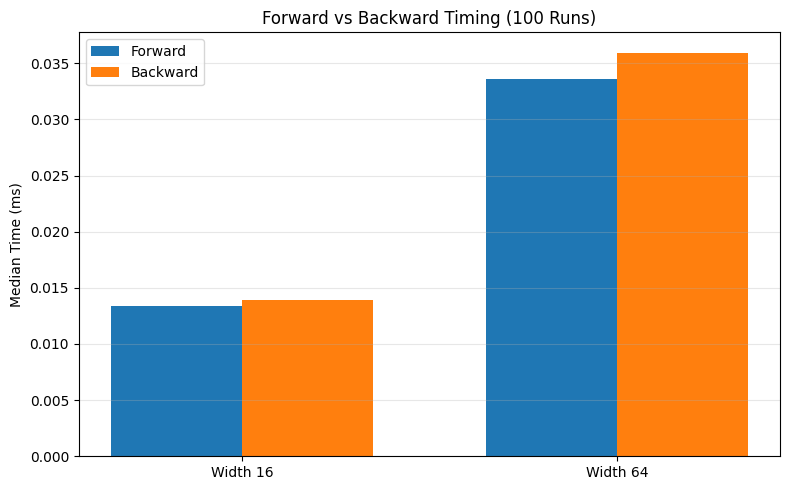

Saved: results/timing_breakdown.png


In [13]:

# Plot timing comparison

widths = [16, 64]

forward_values = [
    timing_results[w][0] for w in widths
]

backward_values = [
    timing_results[w][1] for w in widths
]

x = np.arange(len(widths))
bar_width = 0.35

plt.figure(figsize=(8, 5))

plt.bar(
    x - bar_width / 2,
    forward_values,
    bar_width,
    label="Forward"
)

plt.bar(
    x + bar_width / 2,
    backward_values,
    bar_width,
    label="Backward"
)

plt.xticks(x, ["Width 16", "Width 64"])
plt.ylabel("Median Time (ms)")
plt.title("Forward vs Backward Timing (100 Runs)")
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig(
    "results/timing_breakdown.png",
    dpi=150
)

plt.show()

print("Saved: results/timing_breakdown.png")



# Lab 2 — Neural Network from Scratch

## 1. Objective

The objective of this laboratory is to implement a
two-hidden-layer neural network from scratch using NumPy
and evaluate its performance on the load_digits dataset.

## 2. Dataset Preparation

The load_digits dataset contains 1797 handwritten digit
images. Each image consists of 8 × 8 pixels.

The pixel values were normalized by dividing by 16.
The labels were converted to one-hot encoding.

The dataset was split into 70% training and 30% testing
using stratified sampling with random_state=42.

## 3. Neural Network Architecture

The neural network consists of:

- Input layer: 64 neurons
- Hidden layer 1: 16 or 64 neurons, ReLU
- Hidden layer 2: 16 or 64 neurons, ReLU
- Output layer: 10 neurons, Softmax

Weight matrices have shapes (64, W), (W, W), and (W, 10).
Bias vectors have shapes (W,), (W,), and (10,).

Weights were initialized with small random values
from a normal distribution with standard deviation 0.01.

## 4. Forward Propagation

The forward pass is computed using:

$$Z_1 = XW_1 + b_1$$

$$A_1 = ReLU(Z_1)$$

$$Z_2 = A_1W_2 + b_2$$

$$A_2 = ReLU(Z_2)$$

$$Z_3 = A_2W_3 + b_3$$

$$P = Softmax(Z_3)$$

Softmax converts the output scores into probabilities.

## 5. Loss Function

Cross-entropy loss was used to measure prediction error.

$$L = -\frac{1}{m}\sum_{i=1}^{m}
\sum_{k=1}^{10} y_{ik}\log(p_{ik})$$

The initial loss was approximately 2.3026,
which agrees with the expected value ln(10).

## 6. Backpropagation

Gradients were computed using the chain rule.

For the output layer:

$$dZ_3 = (P-Y)/m$$

$$dW_3 = A_2^T dZ_3$$

$$db_3 = \sum dZ_3$$

For the second hidden layer:

$$dZ_2 = (dZ_3 W_3^T) \odot ReLU'(Z_2)$$

$$dW_2 = A_1^T dZ_2$$

$$db_2 = \sum dZ_2$$

For the first hidden layer:

$$dZ_1 = (dZ_2 W_2^T) \odot ReLU'(Z_1)$$

$$dW_1 = X^T dZ_1$$

$$db_1 = \sum dZ_1$$

The symbol $\odot$ represents element-wise multiplication.

## 7. Gradient Checking

Numerical gradient checking was performed using
central differences with epsilon = 1e-5.

All 10 selected weights passed the gradient check,
with relative errors below 1e-6.

## 8. Model Training

The models were trained for 50 epochs using
mini-batch gradient descent with batch size 32.

The learning rates were 0.001, 0.01, and 0.1.
The hidden layer widths were 16 and 64.

A total of six configurations were tested.

## 9. Performance Evaluation

The best accuracy observed in the initial experiment
was 93.89%, using hidden width 64 and learning rate 0.1.

Smaller learning rates showed slower convergence
within the specified 50 epochs.

## 10. Computational Timing

Forward and backward propagation were measured
separately using the median of 100 runs.

Backward propagation generally requires additional
matrix multiplications for computing gradients.

The timing results are provided in the results folder.

## 11. Conclusion

A two-hidden-layer neural network was successfully
implemented using NumPy.

The experiment demonstrated the importance of
learning rate, hidden layer width, gradient checking,
and computational efficiency.
